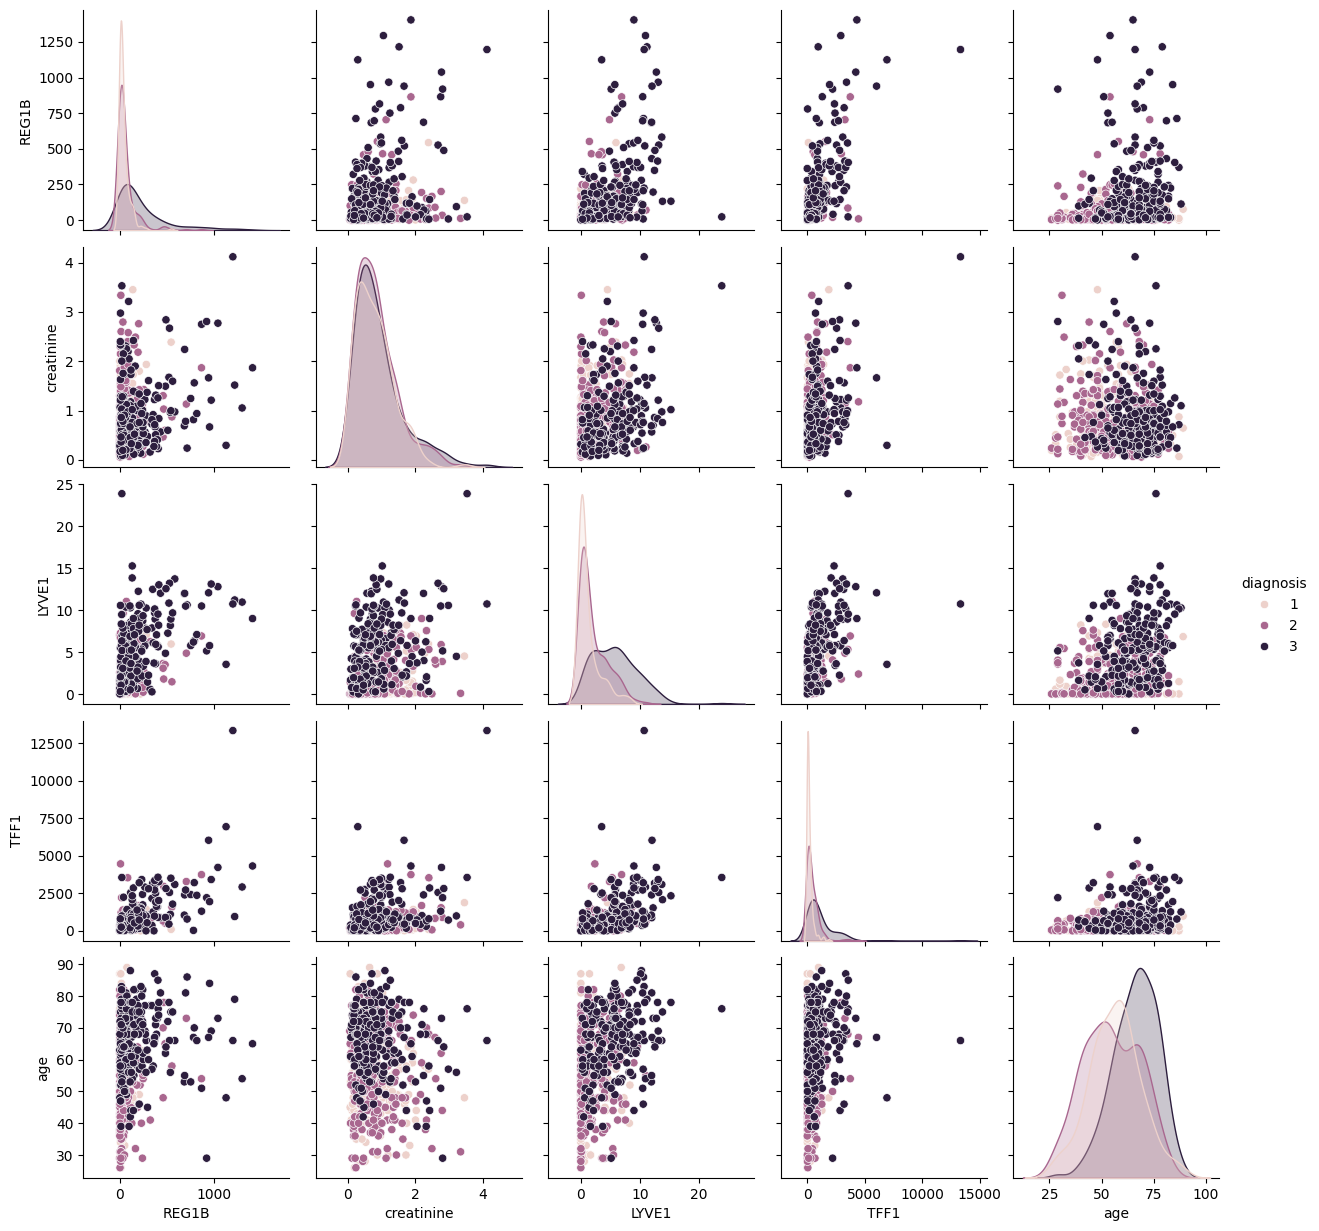

In [23]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
from sklearn.tree import plot_tree
from sklearn.impute import SimpleImputer
import pandas as pd
import seaborn as sns 

df=pd.read_csv(r'C:\Users\choua\Desktop\kaggle dataset\urinary_pancreatic_cancer\Debernardi et al 2020 data.csv')

df.drop(['sex'], axis=1, inplace=True)
df.drop(['sample_id'], axis=1, inplace=True)
x=df.drop(['diagnosis'], axis=1)
y=df['diagnosis']
sns.pairplot(data = df, vars=['REG1B', 'creatinine', 'LYVE1', 'TFF1', 'age'], hue='diagnosis', diag_kind='kde')


c:\Users\choua\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\matrix.py:202: RuntimeWarning: All-NaN slice encountered
  vmin = np.nanmin(calc_data)
c:\Users\choua\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\matrix.py:207: RuntimeWarning: All-NaN slice encountered
  vmax = np.nanmax(calc_data)


<Axes: >

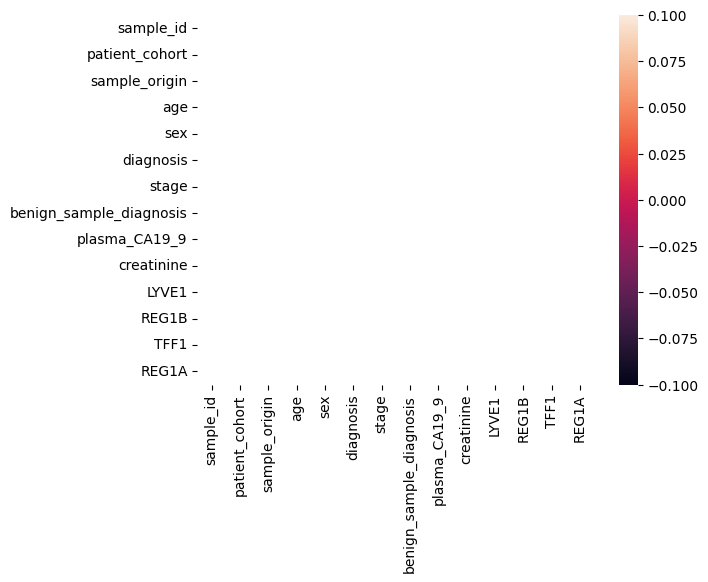

In [19]:
corr = df.dropna().corr()
sns.heatmap(corr, annot=True)

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import accuracy_score

df = pd.read_csv(r'C:\Users\choua\Desktop\kaggle dataset\urinary_pancreatic_cancer\Debernardi et al 2020 data.csv')
X = df.drop('diagnosis', axis=1)
y = df['diagnosis']
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object']).columns
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

numeric_transformer = Pipeline([('imputer', SimpleImputer(strategy='mean'))])
categorical_transformer = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore'))])
preprocessor = ColumnTransformer(transformers=[('num', numeric_transformer, numeric_features), ('cat', categorical_transformer, categorical_features)])
pipeline = Pipeline([('preprocessor', preprocessor), ('rf', RandomForestClassifier())])

param_grid = {'rf__n_estimators': [100], 'rf__max_depth': [None, 5, 10]}
grid_search = GridSearchCV(pipeline, param_grid, cv=10, n_jobs=-1)
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

best_preprocessor = best_model.named_steps['preprocessor']
preprocessed_feature_names = numeric_features.tolist()
for name, trans, cols in best_preprocessor.transformers_:
    if name == 'cat':
        encoded_names = trans.named_steps['encoder'].get_feature_names_out(categorical_features)
        preprocessed_feature_names.extend(encoded_names)

importances = best_model.named_steps['rf'].feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(8, 6))
plt.title("Feature importances")
plt.barh(range(len(importances)), importances[indices], color="r", align="center")
plt.yticks(range(len(importances)), np.array(preprocessed_feature_names)[indices])
plt.ylim([-1, len(importances)])
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
plt.show()


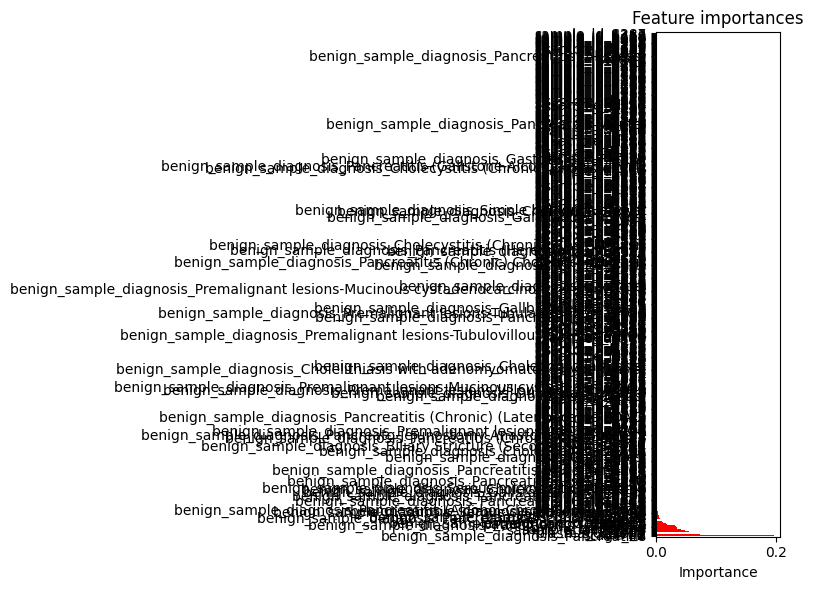

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import accuracy_score

df = pd.read_csv(r'C:\Users\choua\Desktop\kaggle dataset\urinary_pancreatic_cancer\Debernardi et al 2020 data.csv')
X = df.drop('diagnosis', axis=1)
y = df['diagnosis']
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object']).columns
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

numeric_transformer = Pipeline([('imputer', SimpleImputer(strategy='mean'))])
categorical_transformer = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore'))])
preprocessor = ColumnTransformer(transformers=[('num', numeric_transformer, numeric_features), ('cat', categorical_transformer, categorical_features)])
pipeline = Pipeline([('preprocessor', preprocessor), ('rf', RandomForestClassifier())])

param_grid = {'rf__n_estimators': [100], 'rf__max_depth': [None, 5, 10]}
grid_search = GridSearchCV(pipeline, param_grid, cv=10, n_jobs=-1)
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

best_preprocessor = best_model.named_steps['preprocessor']
preprocessed_feature_names = numeric_features.tolist()
for name, trans, cols in best_preprocessor.transformers_:
    if name == 'cat':
        encoded_names = trans.named_steps['encoder'].get_feature_names_out(categorical_features)
        preprocessed_feature_names.extend(encoded_names)

importances = best_model.named_steps['rf'].feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(8, 6))
plt.title("Feature importances")
plt.barh(range(len(importances)), importances[indices], color="r", align="center")
plt.yticks(range(len(importances)), np.array(preprocessed_feature_names)[indices])
plt.ylim([-1, len(importances)])
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
plt.show()


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, cohen_kappa_score, roc_auc_score, classification_report, balanced_accuracy_score

# Load dataset
df = pd.read_csv(r'C:\Users\choua\Desktop\kaggle dataset\urinary_pancreatic_cancer\Debernardi et al 2020 data.csv')

#df = df.drop(['sample_id'], axis=1)
X = df.drop('diagnosis', axis=1)
y = df['diagnosis']

# Identify numeric and categorical features
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object']).columns

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define preprocessing for each feature type
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='mean')),
            ('scaler', StandardScaler())
        ]), numeric_features),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_features)
    ])

# Full pipeline with preprocessing and classifier
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42))
])

# Fit the pipeline
pipeline.fit(X_train, y_train)

# Cross-validation
cv_scores = cross_val_score(pipeline, X_train, y_train, cv=5, scoring='accuracy')
mean_cv_accuracy = np.mean(cv_scores)

# Predictions
y_train_pred = pipeline.predict(X_train)
y_test_pred = pipeline.predict(X_test)

# Evaluate
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
kappa = cohen_kappa_score(y_test, y_test_pred)

# ✅ Fix: Use multi_class='ovr' for multiclass ROC AUC
auc = roc_auc_score(y_test, pipeline.predict_proba(X_test), multi_class='ovr')

balanced_acc = balanced_accuracy_score(y_test, y_test_pred)

# Print results
print("*****Random Forest Model*****")
print(f"Train Accuracy: {train_accuracy}")
print(f"Test Accuracy: {test_accuracy}")
print(f"Validation Accuracy (Cross-Validation): {mean_cv_accuracy}")
print(f"Cohen's Kappa: {kappa}")
print(f"AUC: {auc}")
print("Classification report: \n", classification_report(y_test, y_test_pred))
print("Balanced accuracy: ", balanced_acc)

*****Random Forest Model*****
Train Accuracy: 1.0
Test Accuracy: 0.9576271186440678
Validation Accuracy (Cross-Validation): 0.9364165733482643
Cohen's Kappa: 0.9364566505115778
AUC: 0.9890785434427579
Classification report: 
               precision    recall  f1-score   support

           1       1.00      0.98      0.99        41
           2       1.00      0.90      0.95        39
           3       0.88      1.00      0.94        38

    accuracy                           0.96       118
   macro avg       0.96      0.96      0.96       118
weighted avg       0.96      0.96      0.96       118

Balanced accuracy:  0.9576818845111528


<Axes: xlabel='sample_id', ylabel='diagnosis'>

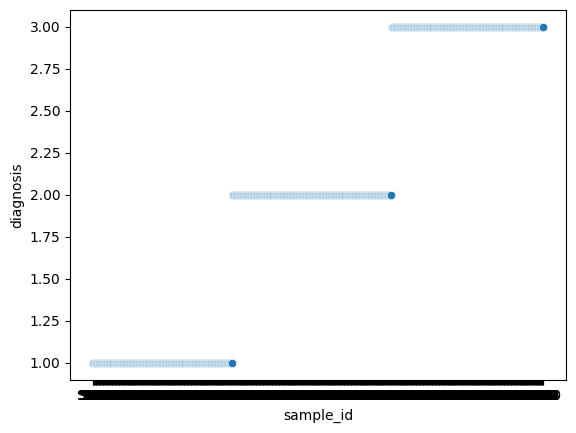

In [10]:
# Check if sample_id correlates with target (unlikely, but possible)
import seaborn as sns
sns.scatterplot(x='sample_id', y='diagnosis', data=df)

In [21]:
#df = df.drop(['sample_id'], axis=1)
# Check feature importances to see how much the model relied on sample_id
import shap
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_train)

NameError: name 'model' is not defined

In [13]:
pip install shap 

  Obtaining dependency information for shap from https://files.pythonhosted.org/packages/f1/43/dd076925ec7544f14cd264cdc2019267bb26029d07e483027d6bddf19630/shap-0.47.2-cp312-cp312-win_amd64.whl.metadata
  Obtaining dependency information for tqdm>=4.27.0 from https://files.pythonhosted.org/packages/d0/30/dc54f88dd4a2b5dc8a0279bdd7270e735851848b762aeb1c1184ed1f6b14/tqdm-4.67.1-py3-none-any.whl.metadata
     ---------------------------------------- 0.0/57.7 kB ? eta -:--:--
     ------- -------------------------------- 10.2/57.7 kB ? eta -:--:--
     -------------------------- ----------- 41.0/57.7 kB 495.5 kB/s eta 0:00:01
     -------------------------------------- 57.7/57.7 kB 608.1 kB/s eta 0:00:00
  Obtaining dependency information for slicer==0.0.8 from https://files.pythonhosted.org/packages/63/81/9ef641ff4e12cbcca30e54e72fb0951a2ba195d0cda0ba4100e532d929db/slicer-0.0.8-py3-none-any.whl.metadata
  Obtaining dependency information for numba>=0.54 from https://files.pythonhosted.org

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 23.2.1 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip
